In [364]:
import pandas as pd

docs = pd.read_csv('CVF Conferences Dataset.csv')
data = docs[docs['CVF Conferences'] == 'ICCV 2021']

c:\Users\TUF Dash F15\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\TUF Dash F15\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\TUF Dash F15\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


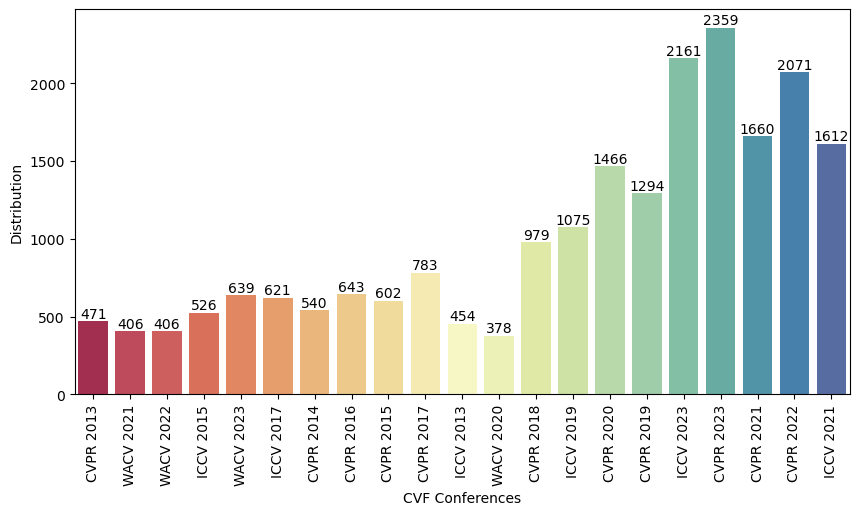

In [365]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
ax = sns.countplot(x=docs['CVF Conferences'], palette=sns.color_palette("Spectral", 21))
for container in ax.containers:
    ax.bar_label(container)
plt.xticks(rotation=90)
plt.ylabel('Distribution')
plt.xlabel('CVF Conferences')
plt.show()

In [366]:
from bs4 import BeautifulSoup
import re

def preprocessing(text):
    new_text = re.sub(r'[\r\n\t]', '', text)
    return BeautifulSoup(new_text, "html.parser").get_text()

In [367]:
for col in data.columns:
    data[col] = data[col].astype(str).apply(preprocessing)

C:\Users\TUF Dash F15\AppData\Local\Temp\ipykernel_23748\3452241379.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].astype(str).apply(preprocessing)
C:\Users\TUF Dash F15\AppData\Local\Temp\ipykernel_23748\2102377892.py:6: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  return BeautifulSoup(new_text, "html.parser").get_text()
C:\Users\TUF Dash F15\AppData\Local\Temp\ipykernel_23748\3452241379.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pand

In [368]:
def cleanText(text):
    text = re.sub('https?:\/\/\S+', '', text) 
    text = re.sub('[^a-zA-Z]', ' ', str(text).lower().strip())
    text = re.sub('#','',text)
    text = re.sub('\d+', '', text)
    text = re.sub('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]+','', text) 
    text = re.sub('\n',' ',text)
    return text

data['Clean Abstract'] = data['Abstract'].apply(cleanText) 

C:\Users\TUF Dash F15\AppData\Local\Temp\ipykernel_23748\2776060486.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Clean Abstract'] = data['Abstract'].apply(cleanText)


In [369]:
from nltk import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

def removeStopwords(text):
    tokens = word_tokenize(text)
    lemmatizer = WordNetLemmatizer()
    clean_text = [lemmatizer.lemmatize(word) for word in tokens if word.lower() not in stopwords.words('english')]
    return ' '.join(clean_text)

data['Clean Abstract'] = data['Clean Abstract'].apply(removeStopwords)

C:\Users\TUF Dash F15\AppData\Local\Temp\ipykernel_23748\1678367959.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Clean Abstract'] = data['Clean Abstract'].apply(removeStopwords)


In [370]:
def removeSuffix(text):
    text = re.sub(r'\b(\w+?)s\b', r'\1', text)
    return text
data['Clean Abstract'] = data['Clean Abstract'].apply(removeSuffix)
data

C:\Users\TUF Dash F15\AppData\Local\Temp\ipykernel_23748\1139411348.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Clean Abstract'] = data['Clean Abstract'].apply(removeSuffix)


,CVF Conferences,Title,Abstract,Clean Abstract
12742,ICCV 2021,Internal Video Inpainting by Implicit ...,We propose a novel framework for video inp...,propose novel framework video inpainting adopt...
12743,ICCV 2021,TransVG: End-to-End Visual Grounding W...,"In this paper, we present a neat yet effec...",paper present neat yet effective transformer b...
12744,ICCV 2021,Oriented R-CNN for Object Detection,Current state-of-the-art two-stage detecto...,current state art two stage detector generate ...
12745,ICCV 2021,Airbert: In-Domain Pretraining for Vis...,Vision-and-language navigation (VLN) aims ...,vision language navigation vln aim enable embo...
12746,ICCV 2021,Learn To Match: Automatic Matching Net...,Siamese tracking has achieved groundbreaki...,siamese tracking achieved groundbreaking perfo...
...,...,...,...,...
18316,ICCV 2021,Entropy Maximization and Meta Classifi...,Deep neural networks (DNNs) for the semant...,deep neural network dnn semantic segmentation ...
18318,ICCV 2021,FOVEA: Foveated Image Magnification fo...,Efficient processing of high-resolution vi...,efficient processing high resolution video str...
18319,ICCV 2021,C2N: Practical Generative Noise Modeli...,Learning-based image denoising methods hav...,learning based image denoising method bounded ...
18321,ICCV 2021,Continual Learning on Noisy Data Strea...,Continually learning in the real world mus...,continually learning real world must overcome ...


In [371]:
import gensim
from gensim import corpora

from nltk.tokenize import word_tokenize 
from nltk.probability import FreqDist

from gensim.models import CoherenceModel
from gensim.corpora import Dictionary

In [372]:
import nltk

def word_tokenize_wrapper(text):
    gram = [' '.join(e) for e in nltk.ngrams(text.split(), 1)]
    return gram

In [373]:
total_topics = 10
number_words = 10

In [374]:
def coherenceCalc(tokenized_documents):
    dictionary = corpora.Dictionary(tokenized_documents)
    corpus = [dictionary.doc2bow(doc) for doc in tokenized_documents]

    coherence_model = CoherenceModel(texts=tokenized_documents,
                                    corpus=corpus,
                                    dictionary=dictionary,
                                    coherence='c_v')
    coherence = coherence_model.get_coherence()
    return coherence

In [375]:
def lda_model_with_coherence(data, total_topics, number_words):
    data = data.tolist()
    dictionary = corpora.Dictionary(data)
    term_matrix = [dictionary.doc2bow(doc) for doc in data]

    lda_model = gensim.models.ldamodel.LdaModel(term_matrix, num_topics=total_topics, id2word=dictionary)

    topics = lda_model.show_topics(num_topics=total_topics, num_words=number_words, formatted=False)

    out = []
    for i, (topic_idx, topic) in enumerate(topics):
        topic_keywords = [word[0] for word in topic]
        coherence = coherenceCalc([topic_keywords])  # Calculate coherence for each topic
        out.append({'topic_id': topic_idx, 'keywords': topic_keywords, 'coherence': coherence})

    return lda_model, out

In [376]:
from gensim import corpora
from gensim.models.coherencemodel import CoherenceModel

def coherenceCalc(topics, tokenized_documents):
    dictionary = corpora.Dictionary(tokenized_documents)
    corpus = [dictionary.doc2bow(doc) for doc in tokenized_documents]

    coherence_values = []
    for topic in topics:
        coherence_model = CoherenceModel(topics=[topic],
                                        texts=tokenized_documents,
                                        corpus=corpus,
                                        dictionary=dictionary,
                                        coherence='c_v')
        coherence_values.append(coherence_model.get_coherence())

    return coherence_values

def lda_model_with_coherence(data, total_topics, number_words):
    data = data.tolist()
    dictionary = corpora.Dictionary(data)
    term_matrix = [dictionary.doc2bow(doc) for doc in data]

    lda_model = gensim.models.ldamodel.LdaModel(term_matrix, num_topics=total_topics, id2word=dictionary)

    topics = lda_model.show_topics(num_topics=total_topics, num_words=number_words, formatted=False)

    topic_keywords = [[word[0] for word in topic] for topic_idx, topic in topics]

    coherence_values = coherenceCalc(topic_keywords, data)

    out = []
    for i, (topic_idx, topic) in enumerate(topics):
        topic_keywords = [word[0] for word in topic]
        out.append({'topic_id': topic_idx, 'keywords': topic_keywords, 'coherence': coherence_values[i]})

    return lda_model, out

cvpr_2015 = data['Clean Abstract'].apply(word_tokenize_wrapper)
total_topics = 10
number_words = 10

lda_model, topics_data = lda_model_with_coherence(cvpr_2015, total_topics, number_words)

for topic in topics_data:
    print('Topic ID:', topic['topic_id'], '| Keywords:', topic['keywords'], '| Coherence Score:', topic['coherence'])


Topic ID: 0 | Keywords: ['method', 'image', 'learning', 'dataset', 'propose', 'model', 'point', 'video', 'feature', 'based'] | Coherence Score: 0.31904017313709115
Topic ID: 1 | Keywords: ['image', 'method', 'model', 'network', 'propose', 'learning', 'based', 'task', 'approach', 'object'] | Coherence Score: 0.3478736454728275
Topic ID: 2 | Keywords: ['image', 'learning', 'method', 'model', 'based', 'network', 'dataset', 'domain', 'data', 'representation'] | Coherence Score: 0.37477091123408257
Topic ID: 3 | Keywords: ['video', 'task', 'method', 'image', 'learning', 'model', 'approach', 'network', 'dataset', 'propose'] | Coherence Score: 0.3424170400073754
Topic ID: 4 | Keywords: ['method', 'image', 'object', 'model', 'video', 'task', 'scene', 'dataset', 'network', 'training'] | Coherence Score: 0.36371807386826327
Topic ID: 5 | Keywords: ['image', 'method', 'model', 'dataset', 'learning', 'feature', 'propose', 'based', 'network', 'show'] | Coherence Score: 0.34198649453039986
Topic ID: